# This notebook calculates 0-D RE evolution during a Disruption

Loading modules

In [1]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [2]:
# Import other modules

import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *

In [ ]:
# Note: You can install missing module using pip install <module_name>
# For example, un-comment the next line to install numpy
#%pip install numpy

# Define Constants

In [8]:
importlib.reload(RE)
from RE import *

# Constants
R0 = 1.85 # Major Radius, [m]
a = 0.57 # Minor Radius, [m]
ni = 3e20 # ion density in plasma fuel, per m**3
L = 1.85e-6 # inductance [H]
k = 1 # elongation

# MGI ion densities
# If we have impurities, specify the impurity denisty here
nD = 1e-11 # Diuterium atoms
nNe = 1e20 # Neon 

# Initial Conditions
I0 = 8.7e6 # [A], Initial Plasma Current
#I0 = 1

## Prescribe the TQ ##
# Here, we assume exponential decay from initial temperature T0 to final temperature Tf.
# (T0 - Tf)* np.exp(-t/t0) + Tf
T0 = 20e3 # eV, initial temperature
Tf = 10 # eV, final temperature
t0 = 0.1e-3 # TQ time [s]

# Print some relevant quantities
Umag = 0.5 * L * I0**2 # Initial magnetic energy, [J]
print('Initial magnetic energy [MJ] = %1.3g'%(Umag/1e6))


Initial magnetic energy [MJ] = 70


# Define the ODEs

The plasma and runaway current evolution is caluclated by solving this set of coupled ODEs.

Here, $I_p$ is the plasma current, $I_{RE}$ is the RE current, $E_\parallel$ is the parallel electric field, $\eta_\parallel(T)$ is the parallel resistivity, $R_0$ is the major radius, and $a$ is the minor radius. $d_t (I_{RE})_{primary}$ and $d_t (I_{RE})_{avalanche}$ are the primary and secondary avalnching rates.

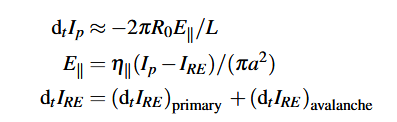

In [10]:
# Here we define the ODEs
def dYdt(t,Y,primary_sources=[1,1,1],iAvalanche=1,nD=1e-10,nNe=1e20):
    # Y[0] = Plasma Current [A]
    # Y[1] = RE current [A]
    # Y[2] = RE Kinetic Energy [J]
    # primary_sources = [iDreicer, iTritium, iCompton], 0 = off
    # iDreicer = 1 Classical; 2 = Hesslow NN
    # iAvalanche = 1 Rosenbluth-PUtvinski, 2 Chiu-Harvey, 3 = Hesslow, 0 = off
    
    Ip, Ir, Wkin = Y
    
    iDreicer, iTritium, iCompton = primary_sources
    
    # Prescribed Thermal Quench
    T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
    # ZNe = getZbarTF(10, 20, SI2cgs(20*nNe*const.m_p,'Mass Density'), T)[0] # caluclate ionization level using LTE Thomas-Fermi model
    ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
    ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
    Zeff = (ni + nD + nNe * ZNe**2) / (ni + nD + nNe * ZNe) # Effective ionization of plasma
    ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
    
    lnA = getCoulombLog(ne,T) # Coulomb logarithm
    eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    Epar = eta*(Ip - Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
    Ec = getConnorHastieField(ne,lnA) # Connor-Hastie Critical Field, [N/C]
    Ed = getDreicerField(ne,lnA,T) # [N/C] Dreicer Field
    E_star = Epar / Ec # Normalized field [-]
    
    
    # Primary Sources
    
    if iDreicer == 1:
        SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
    elif iDreicer == 2:
        SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
    else:
        SD = 0
    
    
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
    
    if T >= 2.6e3:
        SC = getComptonSource(E_star,ntot,'ARC-P') # Use Prompt Flux
    else:
        SC =  getComptonSource(E_star,ntot,'ARC-NP') # Use Non Prompt Flux
        
    # Total Primary Contribution
    S =  SD + iTritium * ST + iCompton * SC # per m3 per s
    j_primary = S * const.c * const.e # A/m**2/s
        
    # Avalanche
    if iAvalanche == 0:
        Yav = 0;
    elif iAvalanche == 1:
         Yav = 1 * iAvalanche * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second
         #if np.random.rand() < 0.1:  # troubleshooting
            #print(f"t={t*1e3:.3f} ms, Yav={Yav:.3e}")
    elif iAvalanche == 2:
        Yav =  1 * get_avalance_growth_rate_CH(E_star,ne,0/R0,lnA,Zeff) # per second
    elif iAvalanche == 3: #Implement getHesslowAvalanchingRate 
     # Define arrays for species info, first element deuterium, second Neon (impurity)
        Z = np.array([1, 10])             # Max ionization of D and Ne
        nj = np.array([nD, nNe])          # Densities [m^-3]
        # trying to use interpolation here
        Zlow = int(np.floor(ZNe))
        Zhigh = int(np.ceil(ZNe))
        weight = ZNe - Zlow # interpolation weight

        # Creating 2 seperate arrays fo the low and high value
        Z0_low = np.array([1, Zlow])
        Z0_high = np.array([1, Zhigh])

        try:
            Y_low = getHesslowAvalanchingRate(E_star, Z, Z0_low, nj, T, element='Ne', B=0)
        except Exception as e:
            Y_low = 0
        try:
            Y_high = getHesslowAvalanchingRate(E_star, Z, Z0_high, nj, T, element='Ne', B=0)
        except Exception as e:
            Y_high = 0

        #Z0 = np.array([1, int(float(ZNe))])           # Current ionization level (using ZNe breaks the array or something??)
        # USE INTERPOLATION FOR ZNe
        #Z0 = np.array([1, 1])
        
        Yav = (1 - weight) * Y_low + weight * Y_high # set has the weighted average of the two
        #if np.random.rand() < 0.1:  # troubleshooting
            #print(f"t={t*1e3:.3f} ms, Yav={Yav:.3e}")
        #print(f"ZNe: {ZNe}   Z0_low: {Z0_low}   Z0_high: {Z0_high}   Yav: {Yav}")
    
    dIpdt = -2 * np.pi * R0 * Epar / L # [A/s]
    dIrdt = j_primary * np.pi * a**2 + Yav * Ir # [A/s]
    if (E_star > 1):
        dWkindt = 2 * np.pi * R0 * Ir * Epar
    else:
        dWkindt = 0
    
    return [dIpdt, dIrdt, dWkindt]

# Solve

In [11]:
from scipy.integrate import solve_ivp
t = np.linspace(0,10e-3,4000) # times to solve at [s]

# testing hesslow avalanching
iDreicer, iTritium, iCompton = 0, 0, 0 # Set Primary Sources
iAvalanche = 3 # Set Avalanche Source
Ir0 = 1 # [A], Initial RE Current
primary_sources=[iDreicer, iTritium, iCompton] # [iDreicer, iTritium, iCompton]
sol = solve_ivp(dYdt, t_span=(0,max(t)), y0 = [I0,Ir0,0],t_eval=t,args=(primary_sources,iAvalanche,nD,nNe)) # Solve
print(sol)

# original
iDreicer, iTritium, iCompton = 0, 0, 0 # Set Primary Sources
iAvalanche = 1 # Set Avalanche Source
Ir0 = 1 # [A], Initial RE Current
primary_sources=[iDreicer, iTritium, iCompton] # [iDreicer, iTritium, iCompton]
sol2 = solve_ivp(dYdt, t_span=(0,max(t)), y0 = [I0,Ir0,0],t_eval=t,args=(primary_sources,iAvalanche,nD,nNe)) # Solve
print(sol2)

c:\Users\grace\OneDrive - Wellesley College\Desktop\UROP_Fall2025\RE_Solver\RE.py:783: RuntimeWarning: invalid value encountered in scalar power
  return pstar * (E_star)**(0.5) - (nuS * nuD)**(1/4)
c:\Users\grace\OneDrive - Wellesley College\Desktop\UROP_Fall2025\RE_Solver\RE.py:810: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  pstar = fsolve(fn, 1, args=(E_star,Z,Z0,nj,T))[0] # critical momentum [-]


  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  2.501e-06 ...  9.997e-03  1.000e-02]
        y: [[ 8.700e+06  8.700e+06 ...  5.847e+06  5.847e+06]
            [ 1.000e+00  1.000e+00 ...  5.812e+06  5.812e+06]
            [ 0.000e+00  0.000e+00 ...  2.548e+06  2.548e+06]]
      sol: None
 t_events: None
 y_events: None
     nfev: 212
     njev: 0
      nlu: 0
  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  2.501e-06 ...  9.997e-03  1.000e-02]
        y: [[ 8.700e+06  8.700e+06 ...  4.693e+06  4.693e+06]
            [ 1.000e+00  1.000e+00 ...  4.687e+06  4.687e+06]
            [ 0.000e+00  0.000e+00 ...  2.254e+06  2.254e+06]]
      sol: None
 t_events: None
 y_events: None
     nfev: 182
     njev: 0
      nlu: 0


# Show Solution

Here, we will plot $I_p$ and $I_{RE}$ as a function of time

Plateau Current Hesslow Ne+ [MA] = 5.847
Plateau Current Rosenbluth-Putvinski [MA] = 4.693


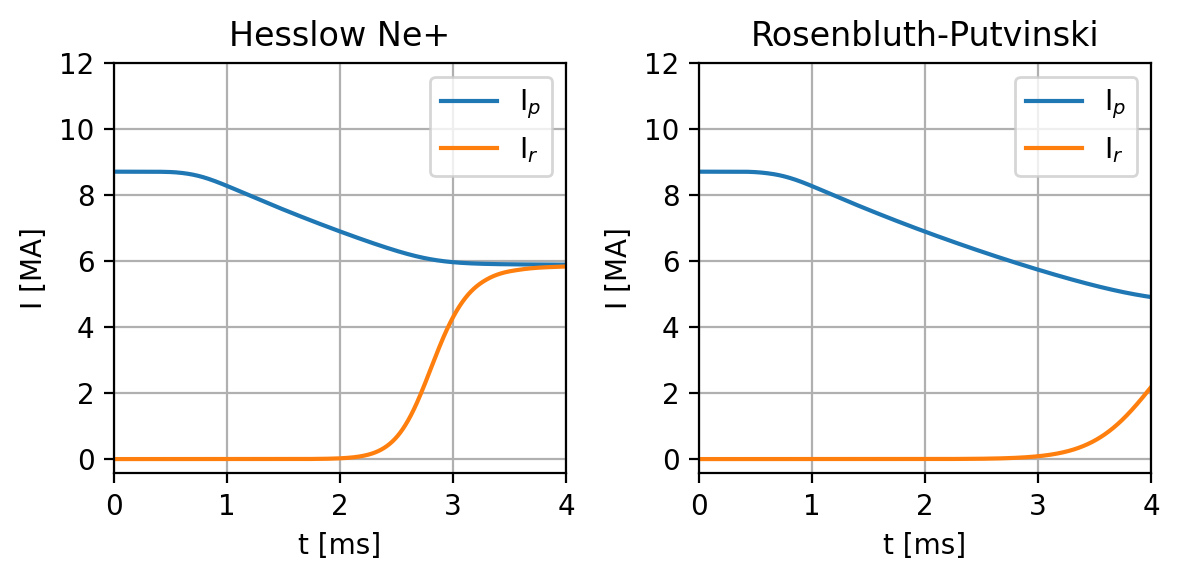

In [12]:
fig, axs = plt.subplots(1,2,figsize=(6,3),dpi=200,sharex=True)
# Hesslow Plot
axs[0].plot(sol.t*1e3,sol.y[0]/1e6,label='I$_p$')
axs[0].plot(sol.t*1e3,sol.y[1]/1e6,label='I$_r$')
axs[0].set_xlabel('t [ms]')
axs[0].set_ylabel('I [MA]')
axs[0].grid()
axs[0].set_yticks(np.arange(0,13,2))
axs[0].legend()
axs[0].set_xlim([0,4])
axs[0].set_title("Hesslow Ne+")

# Original Plot
axs[1].plot(sol2.t*1e3,sol2.y[0]/1e6,label='I$_p$')
axs[1].plot(sol2.t*1e3,sol2.y[1]/1e6,label='I$_r$')
axs[1].set_xlabel('t [ms]')
axs[1].set_ylabel('I [MA]')
axs[1].grid()
axs[1].set_yticks(np.arange(0,13,2))
axs[1].legend()
axs[1].set_xlim([0,4])
axs[1].set_title("Rosenbluth-Putvinski")

#axs[0].legend()
print('Plateau Current Hesslow Ne+ [MA] = %1.3f'%(sol.y[0][-1]/1e6))
print('Plateau Current Rosenbluth-Putvinski [MA] = %1.3f'%(sol2.y[0][-1]/1e6))
fig.tight_layout()


# RE Energy
We can also plot the RE beam energy as a function of time

Plateau Energy [MJ] = 2.548
Average RE Energy [MeV] = 11.306
Plateau Energy [MJ] = 2.254
Average RE Energy [MeV] = 12.401


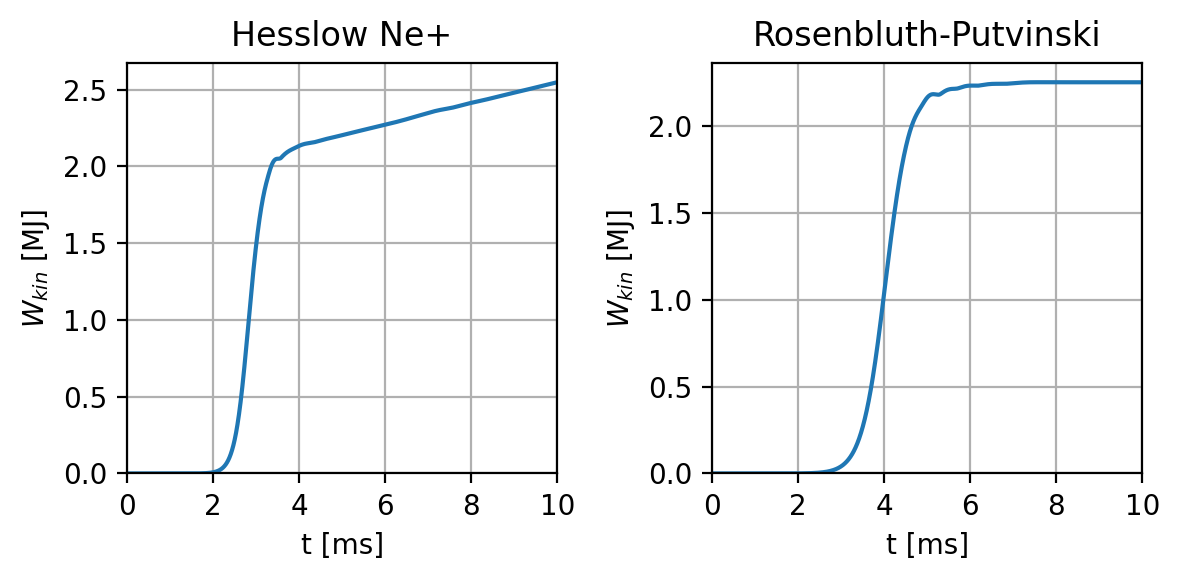

In [13]:
fig, axs = plt.subplots(1,2,figsize=(6,3),dpi=200,sharex=True)
# Hesslow Avalanche 
axs[0].plot(sol.t*1e3,sol.y[2]/1e6)
axs[0].set_xlabel('t [ms]')
axs[0].set_ylabel('$W_{kin}$ [MJ]')
axs[0].grid()
axs[0].set_ylim(ymin=0)
axs[0].set_xlim([0,np.max(sol.t*1e3)])
axs[0].set_title("Hesslow Ne+")
# axs.set_yscale('log')
print('Plateau Energy [MJ] = %1.3f'%(sol.y[2][-1]/1e6))

# Estimate the average Re energy in MeV
N = sol.y[1][-1] * (2 * np.pi * R0) / (const.e * const.c)
avg_energy = sol.y[2][-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))

# RP Avalanche
axs[1].plot(sol2.t*1e3,sol2.y[2]/1e6)
axs[1].set_xlabel('t [ms]')
axs[1].set_ylabel('$W_{kin}$ [MJ]')
axs[1].grid()
axs[1].set_ylim(ymin=0)
axs[1].set_xlim([0,np.max(sol2.t*1e3)])
axs[1].set_title("Rosenbluth-Putvinski")
# axs.set_yscale('log')
print('Plateau Energy [MJ] = %1.3f'%(sol2.y[2][-1]/1e6))

# Estimate the average Re energy in MeV
N = sol2.y[1][-1] * (2 * np.pi * R0) / (const.e * const.c)
avg_energy = sol2.y[2][-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))

fig.tight_layout()

# Show detailed results

<>:65: SyntaxWarning: invalid escape sequence '\p'
<>:67: SyntaxWarning: invalid escape sequence '\p'
<>:75: SyntaxWarning: invalid escape sequence '\g'
<>:88: SyntaxWarning: invalid escape sequence '\,'
<>:65: SyntaxWarning: invalid escape sequence '\p'
<>:67: SyntaxWarning: invalid escape sequence '\p'
<>:75: SyntaxWarning: invalid escape sequence '\g'
<>:88: SyntaxWarning: invalid escape sequence '\,'
C:\Users\grace\AppData\Local\Temp\ipykernel_30904\1712350028.py:65: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_30904\1712350028.py:67: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_30904\1712350028.py:75: SyntaxWarning: invalid escape sequence '\g'
  axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
C:\Users\grace\AppData\Local\Temp\ipykernel_30904\1712350028.py:88: Syn

max E/ED= 0.016643039168870482
max E/ECH= 824.4955631311194
Ed/ECH= 51099.89506917532
max SD=0
max SC=0
max ST==0


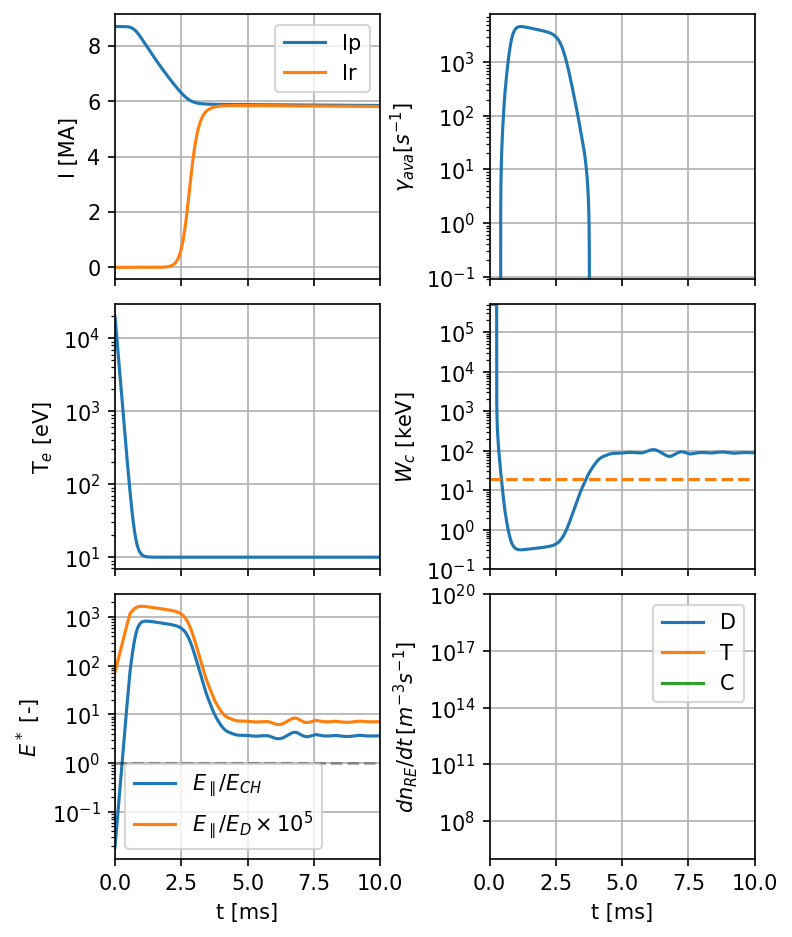

In [14]:
# Get Ip and Ir evolution from the ODE solution
Ip = sol.y[0]
Ir = sol.y[1]

# Calculate other relvant quantities
T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
Zeff = (ni + nD + nNe * ZNe**2) / (ni + nD + nNe * ZNe) # Effective ionization of plasma
ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
lnA = getCoulombLog(ne,T)
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
Epar = eta*(Ip -Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
Ec = getConnorHastieField(ne,lnA) # [N/C]
Ed = getDreicerField(ne,lnA,T) # [N/C]
E_star = Epar / Ec # Normalized field [-]
Wc = getCriticalRunawayEnergy(E_star) / const.eV # eV


# Primary Sources
if iDreicer == 1:
    SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
elif iDreicer == 2:
    SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
else:
    SD = np.zeros_like(E_star)

if iTritium:
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
else:
    ST = 0 * SD
if iCompton:
    SC =  getComptonSource(E_star,ntot,'ARC-P') 
    SC[np.where(T<2.6e3)] = 1e0 * getComptonSource(E_star[np.where(T<2.6e3)],ntot,'ARC-NP') 
else:
    SC = 0 * SD

# Secondary Sources
#Yav =  (ntot / ne) * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second

Z = np.array([1, 10])             # Max ionization of D and Ne
Z0 = np.array([1, 1])           # Current ionization level (using ZNe breaks the array or something??)
nj = np.array([nD, nNe])          # Densities [m^-3]
vec_Hesslow = np.vectorize(
    lambda E, Te: getHesslowAvalanchingRate(E, Z, Z0, nj, Te, element='Ne', B=0)
) #  fn() expects E_star and T to be single numbers, not arrays
# whole arrays fn()’s return shape keeps changing as fsolve 
# need to loop (or vectorize safely) over time points and call getHesslowAvalanchingRate one time-slice at a time
Yav = vec_Hesslow(E_star, T)



############ Plot ##################
fig, axs = plt.subplots(3,2,sharex=True,figsize=(5,6),dpi=150)

axs[0,0].plot(t*1e3,Ip/1e6,label='Ip')
axs[0,0].plot(t*1e3,Ir/1e6,label='Ir')
axs[0,0].set_ylabel('I [MA]')
axs[0,0].legend()

axs[1,0].plot(t*1e3,T)
axs[1,0].set_ylabel('T$_e$ [eV]')
axs[1,0].set_yscale('log')

axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
axs[2,0].plot([0,t.max()*1e3],[1,1],'--',color='k',alpha=0.3)
axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
axs[2,0].set_ylabel('$E^*$ [-]')
axs[2,0].set_yscale('log')
axs[2,0].legend()



axs[0,1].plot(t*1e3,Yav)
axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
axs[0,1].set_yscale('log')

axs[1,1].plot(t*1e3,Wc/1e3)
axs[1,1].plot(t*1e3,18.7*np.ones_like(t),'--')
axs[1,1].set_ylabel('$W_c$ [keV]')
axs[1,1].set_yscale('log')
axs[1,1].set_ylim([1e-1,1e4])
axs[1,1].set_ylim(ymax=getCriticalRunawayEnergy(1) / const.eV / 1e3)

axs[2,1].plot(t*1e3,SD,label='D')
axs[2,1].plot(t*1e3,ST,label='T')
axs[2,1].plot(t*1e3,SC,label='C')
axs[2,1].set_ylabel('$dn_{RE}/dt \, [m^{-3}s^{-1}]$')
axs[2,1].set_yscale('log')
axs[2,1].set_ylim([1e6,1e20])
axs[2,1].legend()


fig.tight_layout(pad=0.5)

for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        axs[i,j].grid()
        axs[i,j].set_xlim([0,np.max(t*1e3)])
        
axs[-1,0].set_xlabel('t [ms]')    
axs[-1,1].set_xlabel('t [ms]')  

# Print Max Values #
print('max E/ED=',np.max(Epar/Ed))
print('max E/ECH=',np.max(E_star))
print('Ed/ECH=',np.max(Ed/Ec))
print('max SD=%1.3g'%np.max(SD))
print('max SC=%1.3g'%np.max(SC))
print('max ST==%1.3g'%np.max(ST))

<>:52: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:62: SyntaxWarning: invalid escape sequence '\g'
<>:75: SyntaxWarning: invalid escape sequence '\,'
<>:52: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:62: SyntaxWarning: invalid escape sequence '\g'
<>:75: SyntaxWarning: invalid escape sequence '\,'
C:\Users\grace\AppData\Local\Temp\ipykernel_30904\3481813278.py:52: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_30904\3481813278.py:54: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_30904\3481813278.py:62: SyntaxWarning: invalid escape sequence '\g'
  axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
C:\Users\grace\AppData\Local\Temp\ipykernel_30904\3481813278.py:75: Syn

max E/ED= 0.016631295746519534
max E/ECH= 823.9010184531785
Ed/ECH= 51099.89506917532
max SD=0
max SC=0
max ST==0


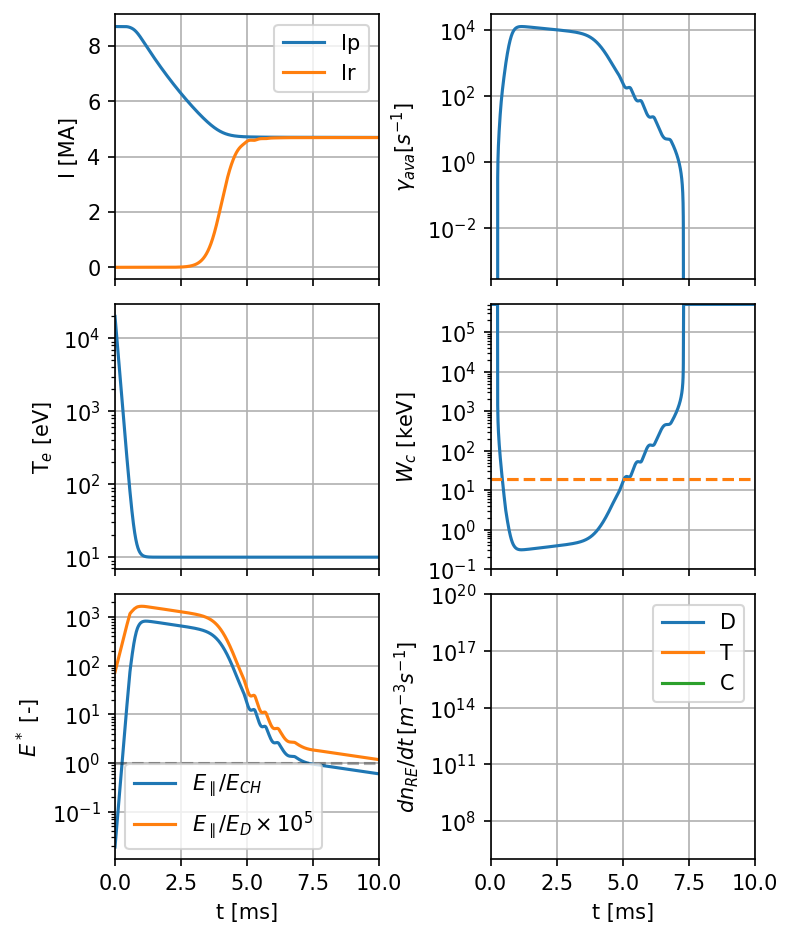

In [15]:
# Get Ip and Ir evolution from the ODE solution
Ip = sol2.y[0]
Ir = sol2.y[1]

# Calculate other relvant quantities
T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
Zeff = (ni + nD + nNe * ZNe**2) / (ni + nD + nNe * ZNe) # Effective ionization of plasma
ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
lnA = getCoulombLog(ne,T)
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
Epar = eta*(Ip -Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
Ec = getConnorHastieField(ne,lnA) # [N/C]
Ed = getDreicerField(ne,lnA,T) # [N/C]
E_star = Epar / Ec # Normalized field [-]
Wc = getCriticalRunawayEnergy(E_star) / const.eV # eV

# Primary Sources
if iDreicer == 1:
    SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
elif iDreicer == 2:
    SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
else:
    SD = np.zeros_like(E_star)

if iTritium:
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
else:
    ST = 0 * SD
if iCompton:
    SC =  getComptonSource(E_star,ntot,'ARC-P') 
    SC[np.where(T<2.6e3)] = 1e0 * getComptonSource(E_star[np.where(T<2.6e3)],ntot,'ARC-NP') 
else:
    SC = 0 * SD

# Secondary Sources
Yav =  (ntot / ne) * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second

############ Plot ##################
fig, axs = plt.subplots(3,2,sharex=True,figsize=(5,6),dpi=150)

axs[0,0].plot(t*1e3,Ip/1e6,label='Ip')
axs[0,0].plot(t*1e3,Ir/1e6,label='Ir')
axs[0,0].set_ylabel('I [MA]')
axs[0,0].legend()

axs[1,0].plot(t*1e3,T)
axs[1,0].set_ylabel('T$_e$ [eV]')
axs[1,0].set_yscale('log')

axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
axs[2,0].plot([0,t.max()*1e3],[1,1],'--',color='k',alpha=0.3)
axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
axs[2,0].set_ylabel('$E^*$ [-]')
axs[2,0].set_yscale('log')
axs[2,0].legend()



axs[0,1].plot(t*1e3,Yav)
axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
axs[0,1].set_yscale('log')

axs[1,1].plot(t*1e3,Wc/1e3)
axs[1,1].plot(t*1e3,18.7*np.ones_like(t),'--')
axs[1,1].set_ylabel('$W_c$ [keV]')
axs[1,1].set_yscale('log')
axs[1,1].set_ylim([1e-1,1e4])
axs[1,1].set_ylim(ymax=getCriticalRunawayEnergy(1) / const.eV / 1e3)

axs[2,1].plot(t*1e3,SD,label='D')
axs[2,1].plot(t*1e3,ST,label='T')
axs[2,1].plot(t*1e3,SC,label='C')
axs[2,1].set_ylabel('$dn_{RE}/dt \, [m^{-3}s^{-1}]$')
axs[2,1].set_yscale('log')
axs[2,1].set_ylim([1e6,1e20])
axs[2,1].legend()


fig.tight_layout(pad=0.5)

for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        axs[i,j].grid()
        axs[i,j].set_xlim([0,np.max(t*1e3)])
        
axs[-1,0].set_xlabel('t [ms]')    
axs[-1,1].set_xlabel('t [ms]')  

# Print Max Values #
print('max E/ED=',np.max(Epar/Ed))
print('max E/ECH=',np.max(E_star))
print('Ed/ECH=',np.max(Ed/Ec))
print('max SD=%1.3g'%np.max(SD))
print('max SC=%1.3g'%np.max(SC))
print('max ST==%1.3g'%np.max(ST))